# H6 — Cambios en el régimen de vientos

Analizamos si la velocidad y la frecuencia de episodios de viento fuerte han variado en Euskal Herria entre 1940 y 2025, y si existe un patrón estacional o geográfico identificable.

## 1. Imports y carga de datos

In [1]:
import sys, os
from pathlib import Path

# Locate project root regardless of where the notebook is launched from
_cwd = Path(os.path.abspath(''))
ROOT = _cwd if (_cwd / 'scripts').exists() else _cwd.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scripts.variables import CIUDADES, crear_dirs
from scripts.funciones_variables import cargar_datos
from scripts.analisis import viento
from scripts.graficos import graficos_viento

crear_dirs()
cargar_datos()

📂 Cargando datos...
  ✅ bilbo: 31,412 filas
  ✅ donostia: 31,412 filas
  ✅ gasteiz: 31,412 filas
  ✅ iruna: 31,412 filas
  ✅ baiona: 31,412 filas
  ✅ arrasate: 31,412 filas
  ✅ maule: 31,412 filas



## 2. Cálculo de todos los indicadores

In [3]:
datos = viento.calcular_todos()

## 3. Velocidad media anual del viento con tendencia lineal

Calculamos la velocidad máxima diaria promediada por año para cada ciudad. La tendencia OLS y el test Mann-Kendall indican si el cambio es estadísticamente significativo.

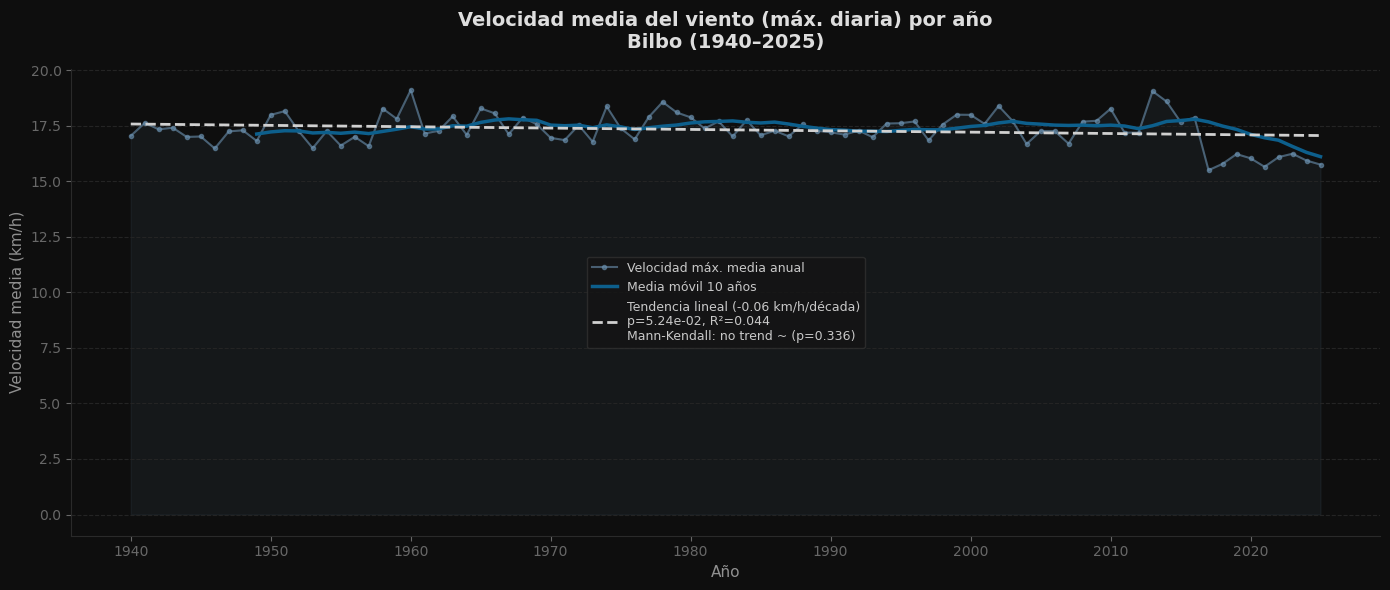

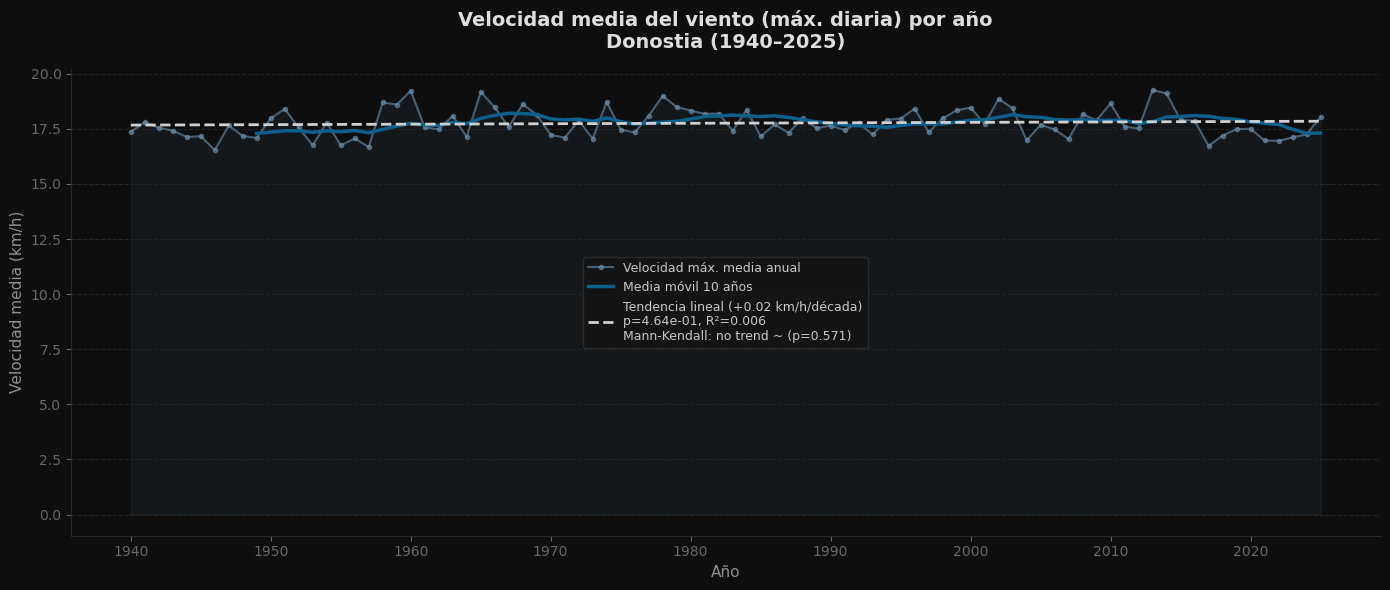

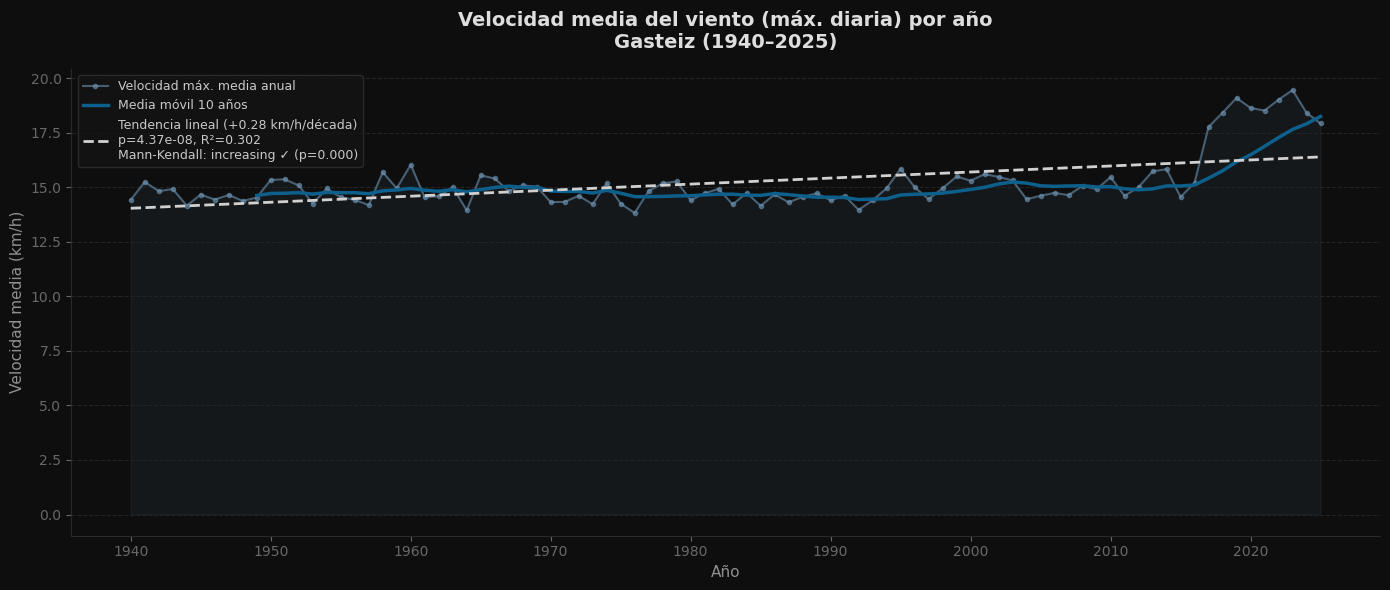

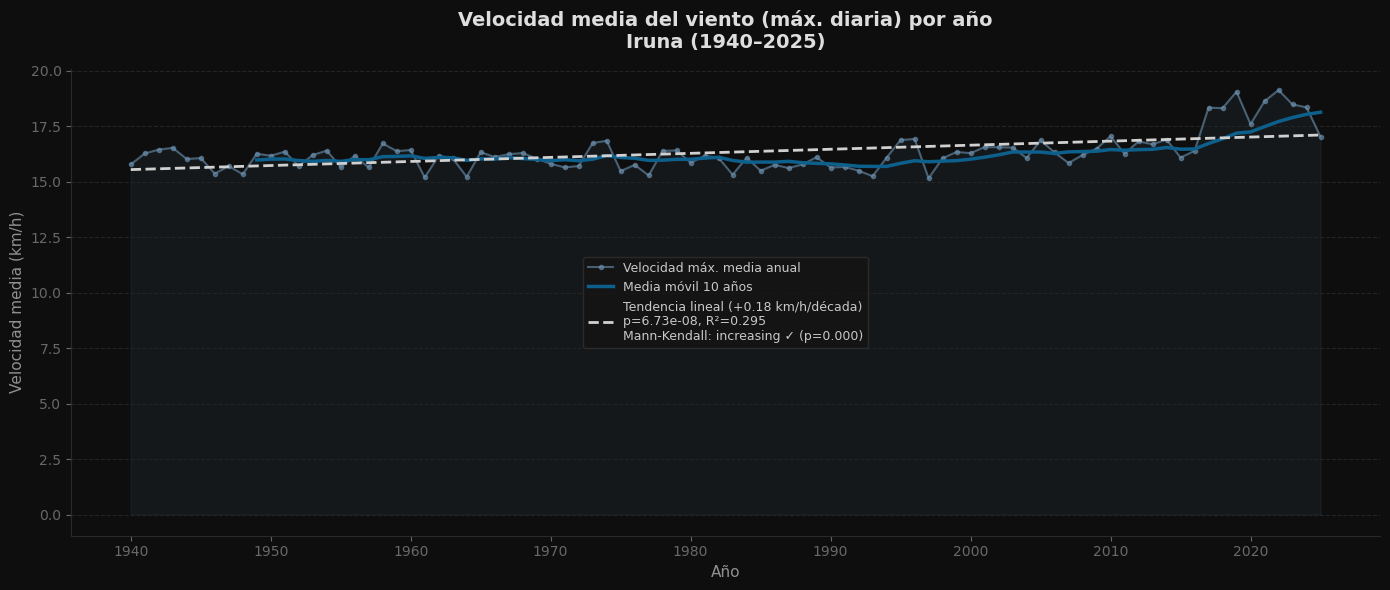

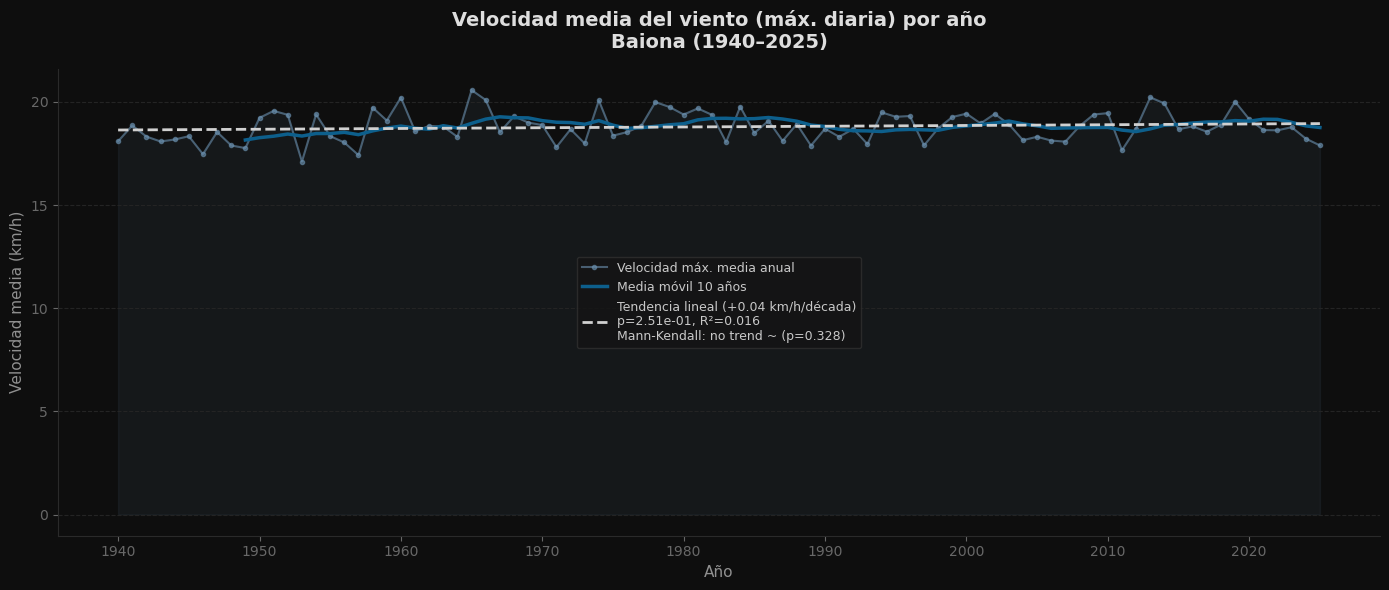

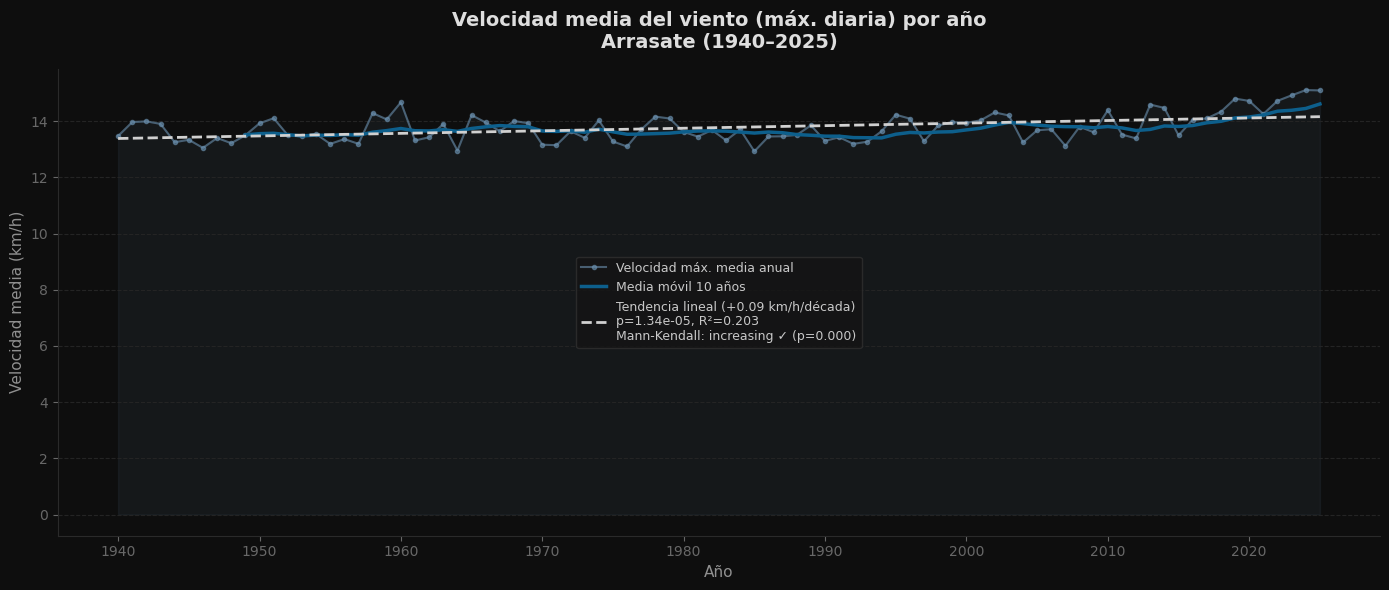

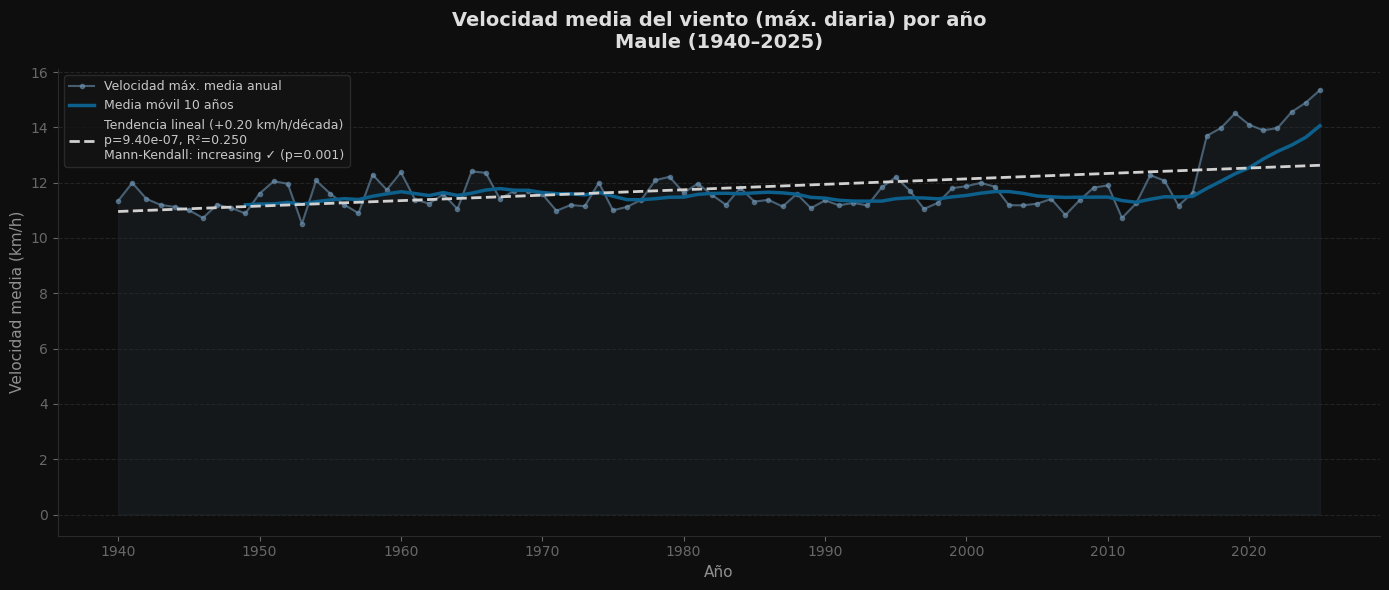

In [4]:
graficos_viento.graficar_viento_anual(datos['viento_anual'])

## 4. Días con viento fuerte (> 50 km/h) por año

Contamos los días en que la velocidad máxima del viento supera los 50 km/h (viento fuerte, Beaufort 7). Las barras se colorean en tres intensidades según la frecuencia.

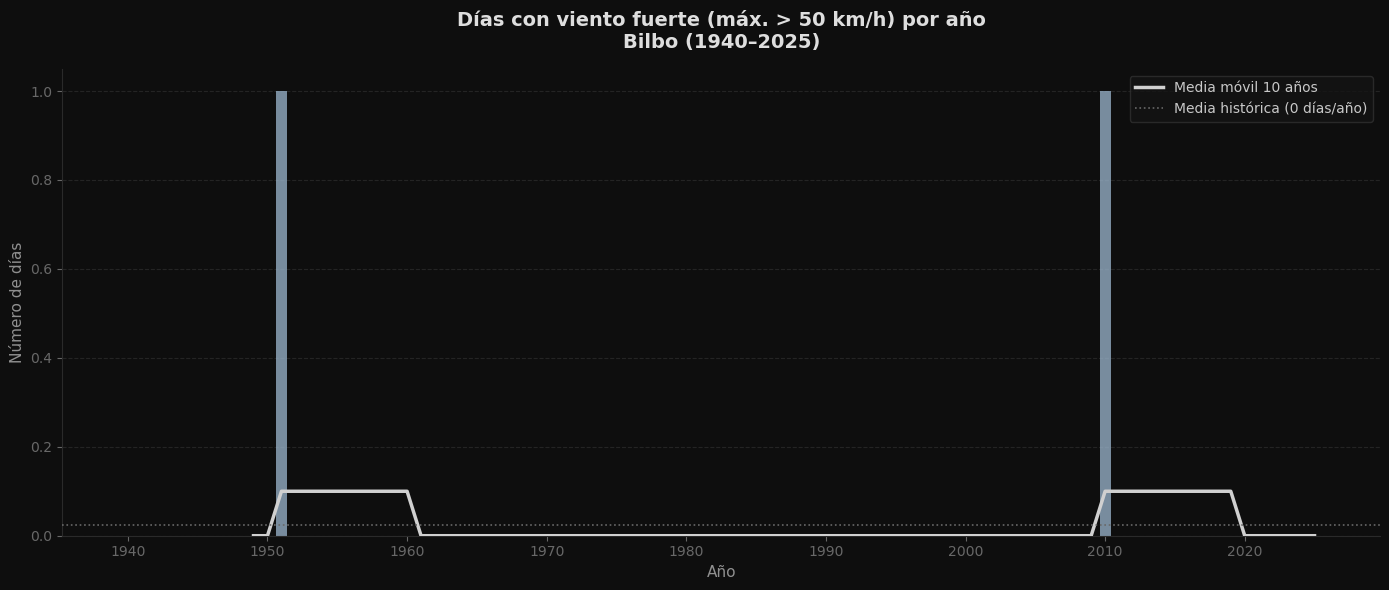

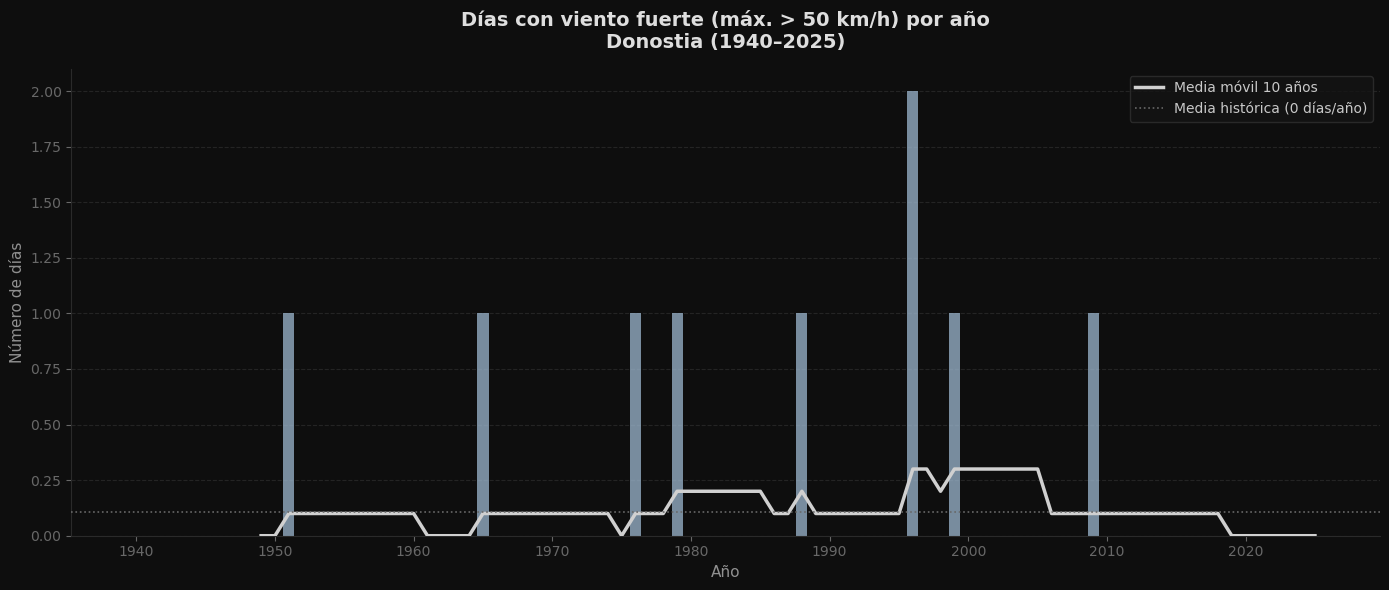

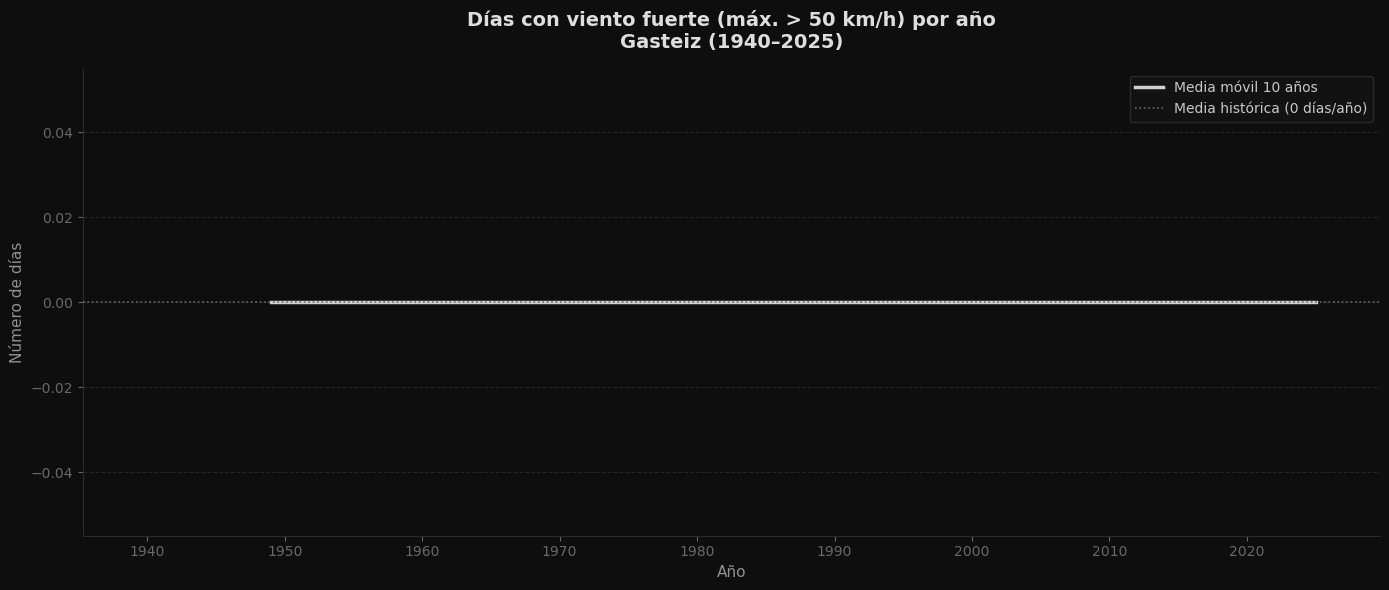

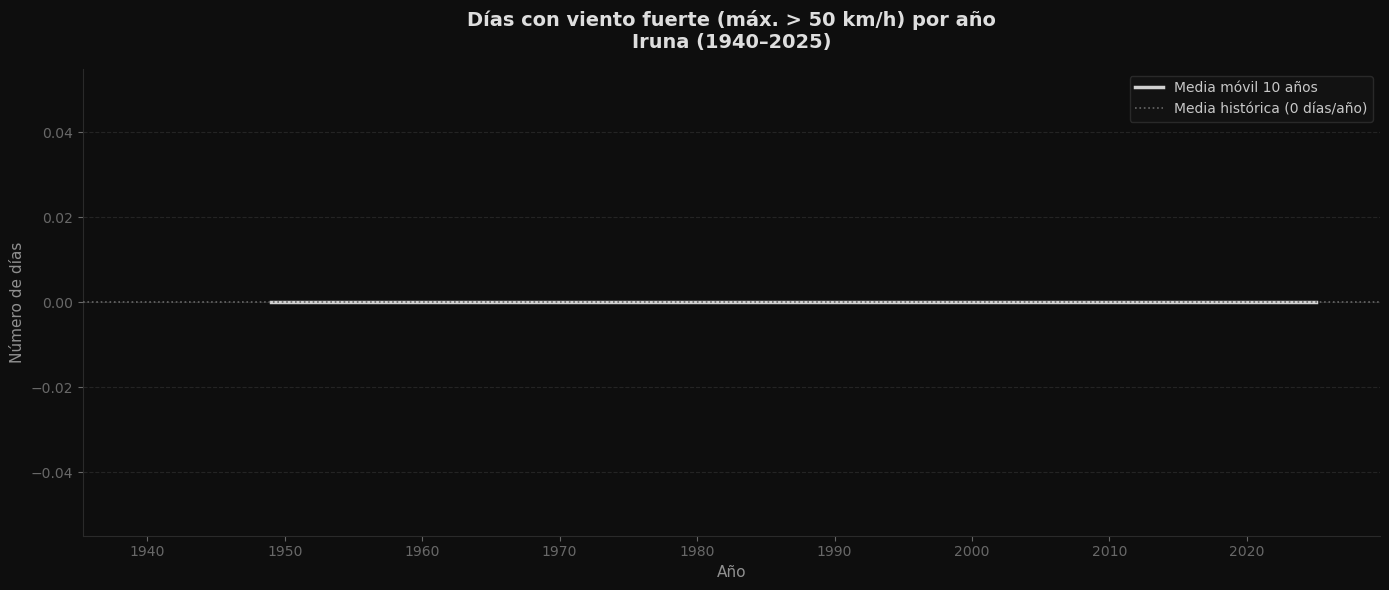

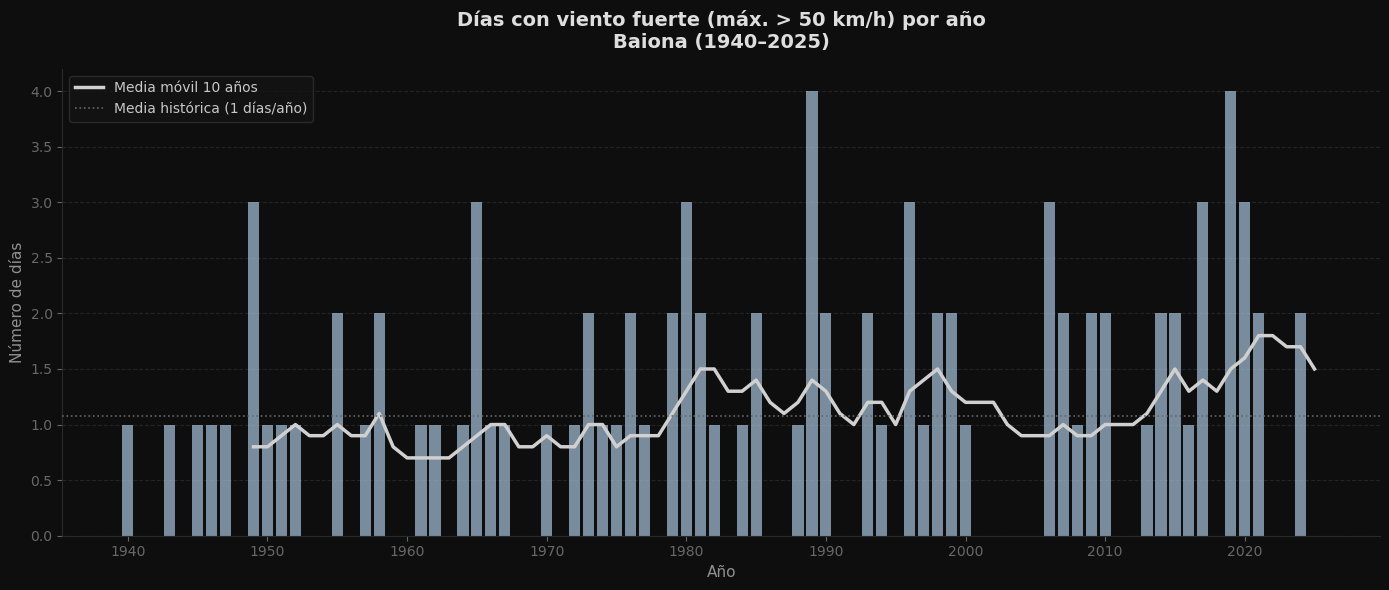

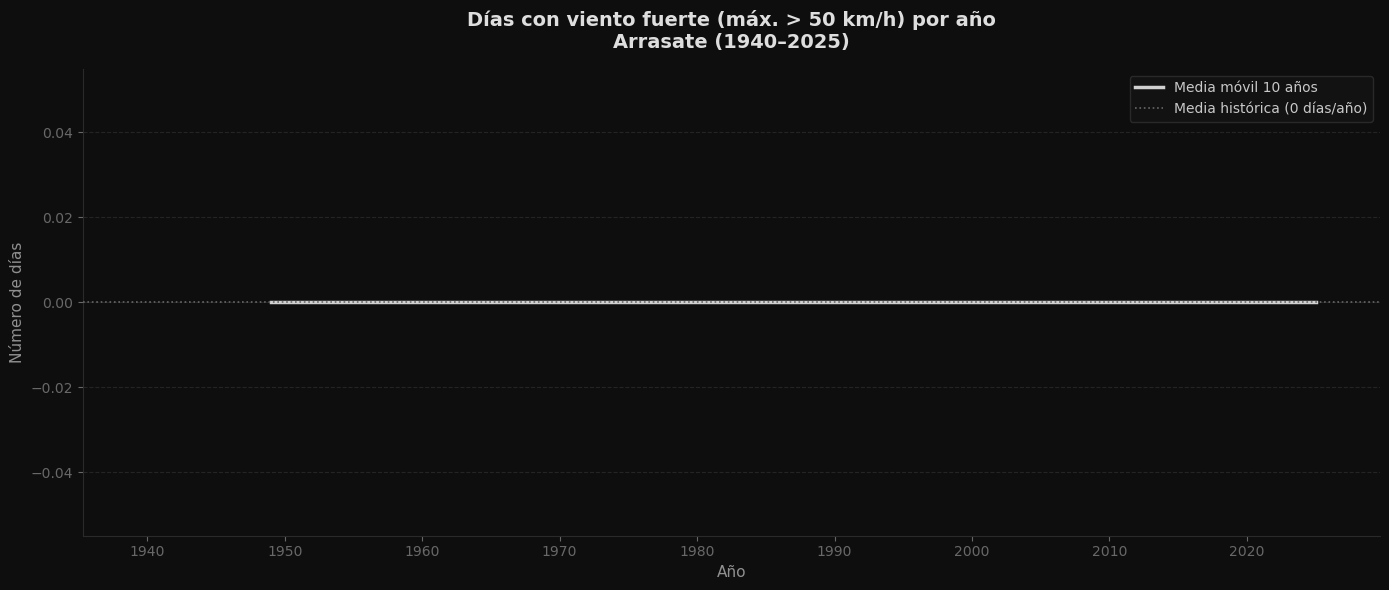

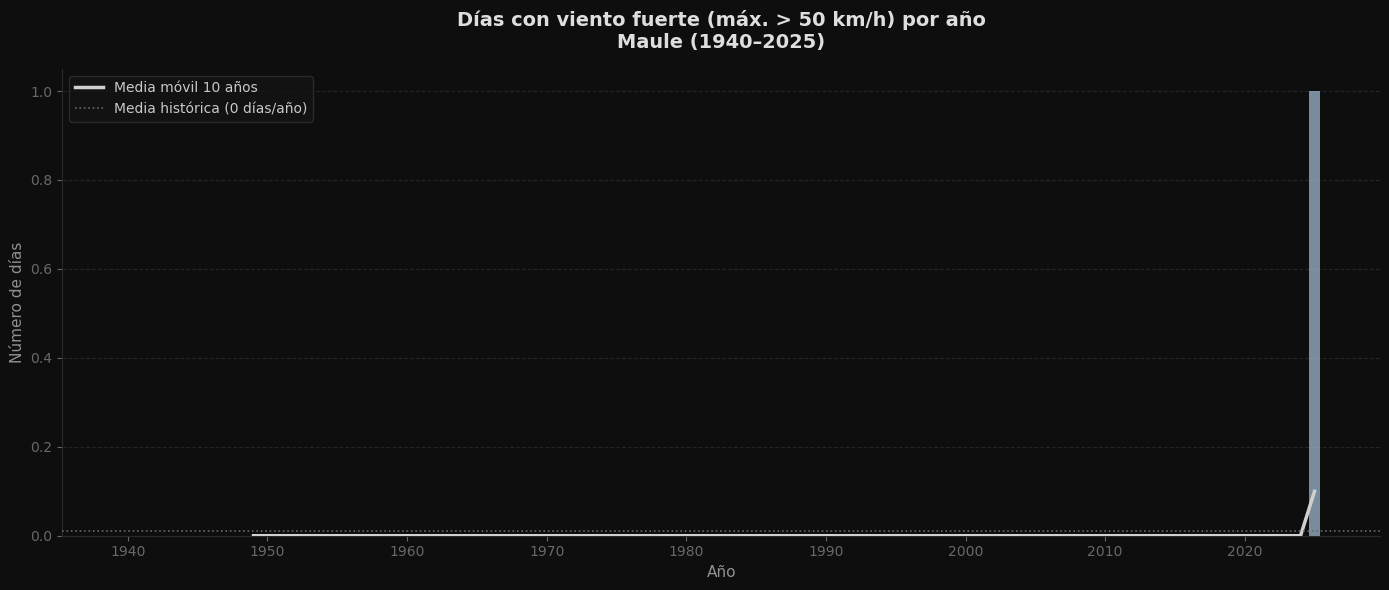

In [5]:
graficos_viento.graficar_dias_viento_fuerte(datos['dias_fuerte'])

## 5. Ciclo estacional del viento — todas las ciudades

Perfil mensual medio de viento para cada ciudad a lo largo de todo el período. Permite identificar los meses más ventosos y las diferencias entre ciudades costeras e interiores.

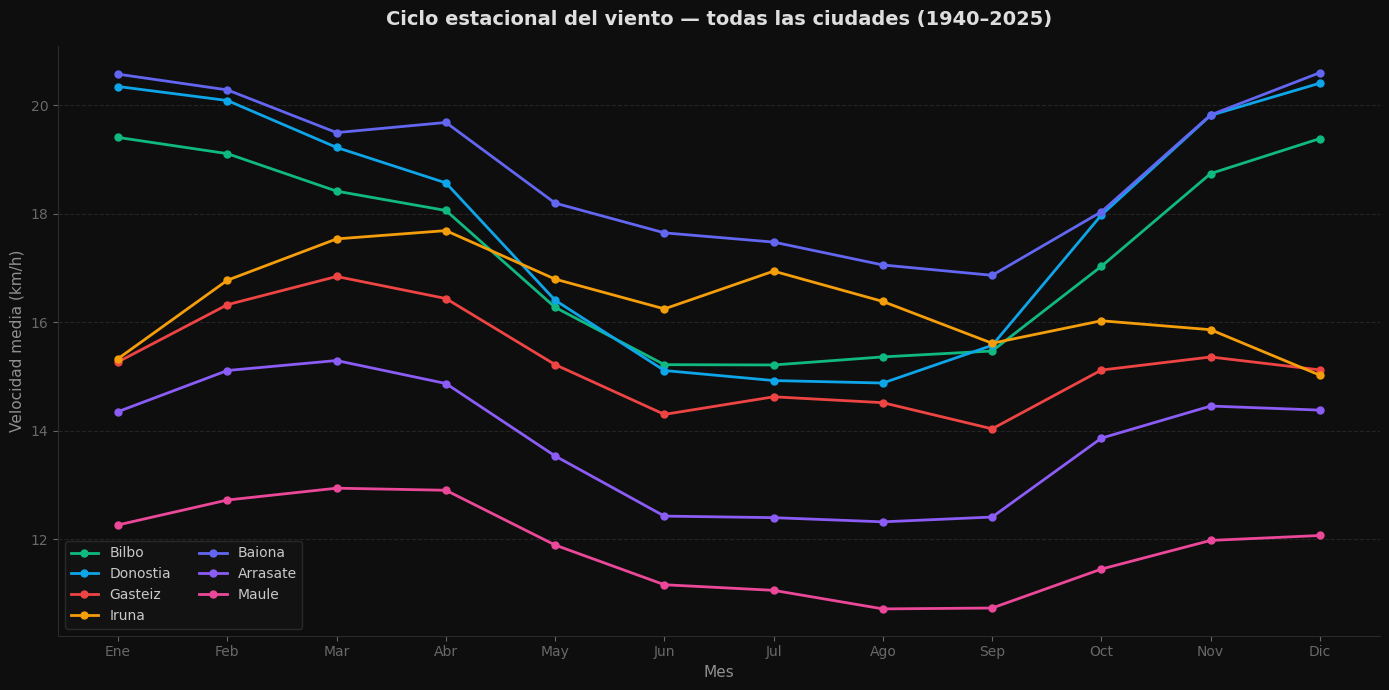

In [6]:
graficos_viento.graficar_perfil_mensual_comparativa(datos)

## 6. Comparativa entre ciudades

Distribución de la velocidad media anual por ciudad, ordenadas por distancia al mar. Muestra si las ciudades costeras reciben más viento que las de interior.

/Users/nora/Documentos_Clase/BOOTCAMP/EDA-Weather-Change-in-Basque-Country/scripts/graficos/graficos_viento.py:146: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/Users/nora/Documentos_Clase/BOOTCAMP/EDA-Weather-Change-in-Basque-Country/scripts/graficos/graficos_viento.py:152: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([n.capitalize() for n in orden])


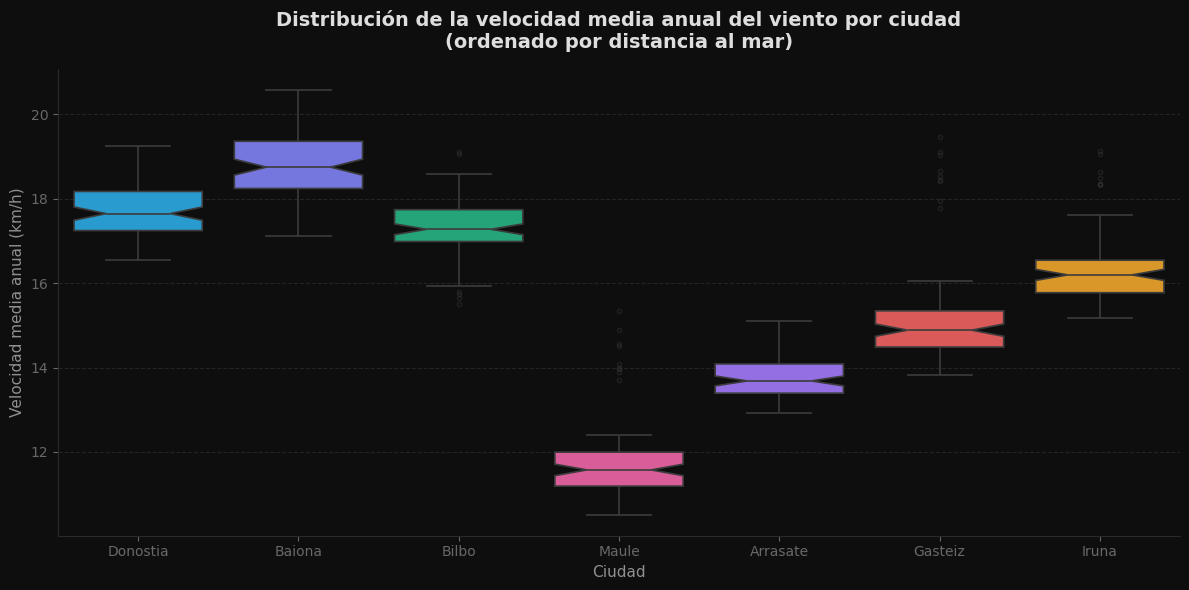

In [7]:
graficos_viento.graficar_comparativa_ciudades(datos)

## 7. Evolución del perfil mensual por períodos históricos

Panel por ciudad comparando el ciclo estacional del viento en tres períodos (1940–1979, 1980–1999, 2000–2025). Una diferencia sistemática entre períodos indicaría un cambio en el régimen de vientos.

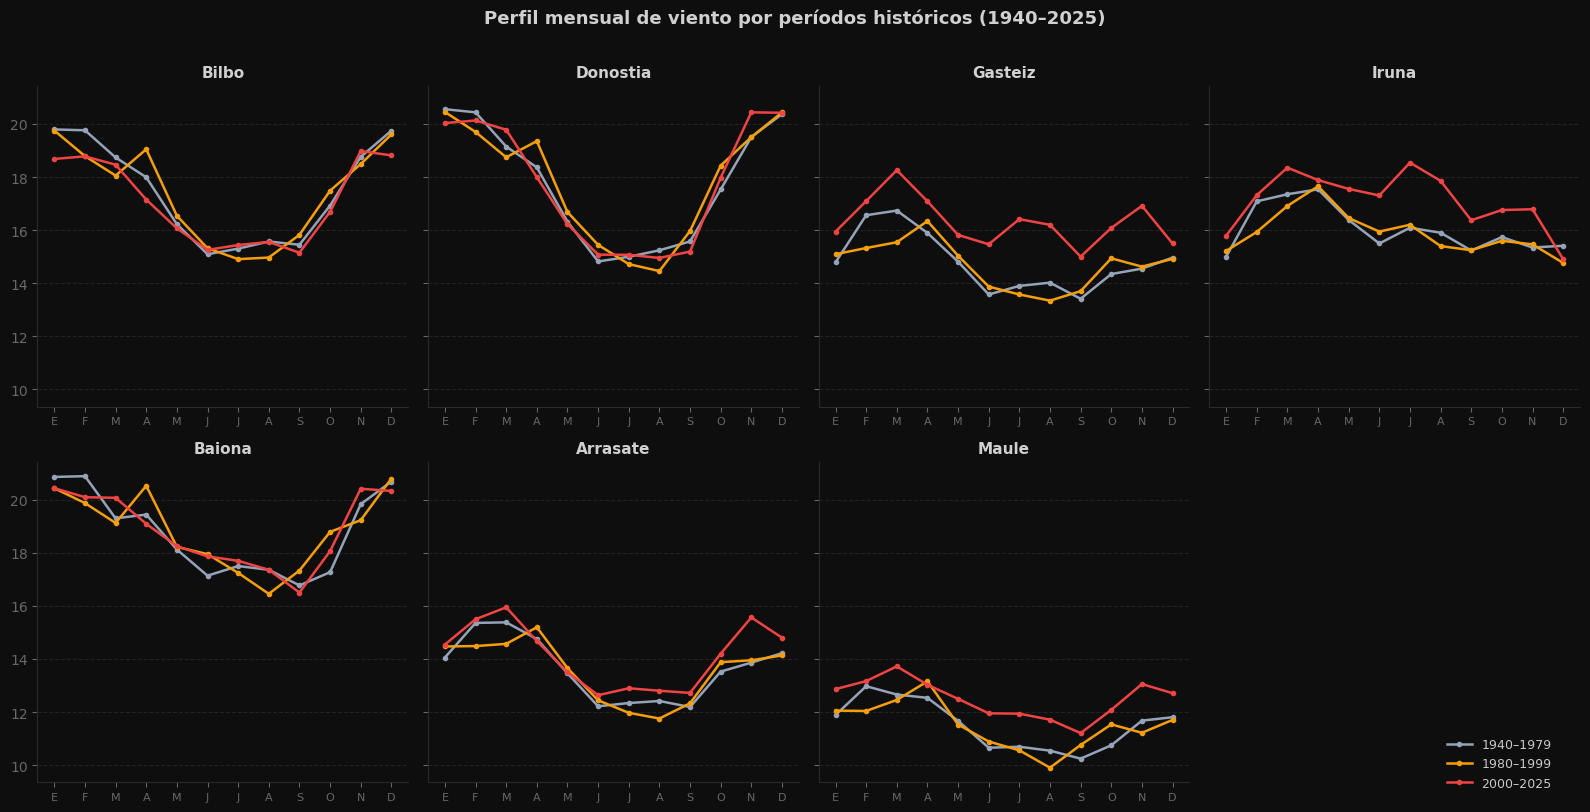

In [8]:
graficos_viento.graficar_periodos_ciudades(datos)

## 8. Resumen estadístico

In [9]:
rows = []
for r in datos['viento_anual']:
    ciudad = r['ciudad']
    slope_dec = r['slope'] * 10
    rows.append({
        'Ciudad':                  ciudad.nombre.capitalize(),
        'Dist. mar (km)':           ciudad.dist_mar,
        'Altitud (m)':              ciudad.altitud,
        'Tendencia (km/h/déc.)':    round(slope_dec, 3),
        'p-valor OLS':              round(r.get('p_value', float('nan')), 4),
        'R²':                       round(r.get('r2', float('nan')), 3),
        'Mann-Kendall':             r.get('mk_trend', ''),
        'MK p-valor':               round(r.get('mk_p', float('nan')), 4),
    })

resumen = pd.DataFrame(rows).sort_values('Tendencia (km/h/déc.)', ascending=False)
display(resumen.style.background_gradient(subset=['Tendencia (km/h/déc.)'], cmap='RdBu_r'))

,Ciudad,Dist. mar (km),Altitud (m),Tendencia (km/h/déc.),p-valor OLS,R²,Mann-Kendall,MK p-valor
2,Gasteiz,58.200000,524,0.277000,0.000000,0.302000,increasing,0.000000
6,Maule,25.200000,144,0.197000,0.000000,0.250000,increasing,0.001400
3,Iruna,61.800000,449,0.183000,0.000000,0.295000,increasing,0.000000
5,Arrasate,33.200000,339,0.091000,0.000000,0.203000,increasing,0.000100
4,Baiona,1.500000,6,0.037000,0.250900,0.016000,no trend,0.328500
1,Donostia,0.000000,5,0.021000,0.464300,0.006000,no trend,0.570800
0,Bilbo,11.100000,19,-0.061000,0.052400,0.044000,no trend,0.335900
